# Bản cải tiến và đáp án đã lưu ngày 16/10/2026

- Dữ liệu thật UCI Steel, nghiên cứu hồi cứu; TEST đã được xem từ trước.
- Chỉ **đọc kết quả đã chạy**, không fit lại hoặc sửa artifact.
- HGB absolute_error được chọn bằng ba fold quá khứ và validation tháng 9.
- MAE tốt hơn nhưng RMSE giờ tới tăng; cảnh báo/quantile không đổi.
- Để kiểm checksum toàn bộ đáp án: `python -m scripts.show_results`.


In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT/'src/steel').is_dir(): ROOT = ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image
RUN = ROOT/'reports/steel/release_2026-10-16'
STUDY = ROOT/'reports/steel/improvements_2026-10-16'
ERROR = ROOT/'reports/steel/error_analysis_2026-10-16'
new = json.loads((RUN/'metrics.json').read_text())
old = json.loads((ROOT/'reports/steel/release_2026-10-14/metrics.json').read_text())
display(pd.DataFrame([{'version':name, **m['splits']['test']['point']} for name,m in [('14/10 squared_error',old),('16/10 absolute_error',new)]]).drop(columns='per_step'))
assert new['splits']['test']['point']['mae_kWh'] < old['splits']['test']['point']['mae_kWh']
print('RMSE tổng giờ tăng:', new['splits']['test']['point']['sum_hour_rmse_kWh'] > old['splits']['test']['point']['sum_hour_rmse_kWh'])


,version,mae_kWh,rmse_kWh,sum_hour_mae_kWh,sum_hour_rmse_kWh
0,14/10 squared_error,5.003358,10.032415,16.066122,31.977080
1,16/10 absolute_error,4.864017,10.217086,15.641525,32.508581


RMSE tổng giờ tăng: True


## Walk-forward và baseline mùa

Ba tháng giữ lại 6/7/8; train chứa quá khứ, nhãn train không chạm tháng giữ lại. Đây là OOF theo thời gian trên các origin được giữ lại, không random K-fold và không dùng để stacking. Scaler chỉ fit TRAIN của mỗi lượt.


,model,origins,weighted_mae_per_step_kWh,weighted_mae_hour_sum_kWh,worst_fold_mae_per_step_kWh
0,last_value,8820,9.289122,33.832759,10.127599
1,seasonal_day,8820,14.260282,53.096645,14.779997
2,seasonal_week,8820,12.365035,45.255861,14.979221
3,ridge,8820,10.644667,37.568722,10.970484
4,hgb,8820,5.602898,17.608952,5.863650
5,hgb_absolute,8820,5.280233,16.726254,5.528121
6,hgb_small,8820,5.700882,18.037852,5.906698
7,lightgbm,8820,5.293247,16.812418,5.510299


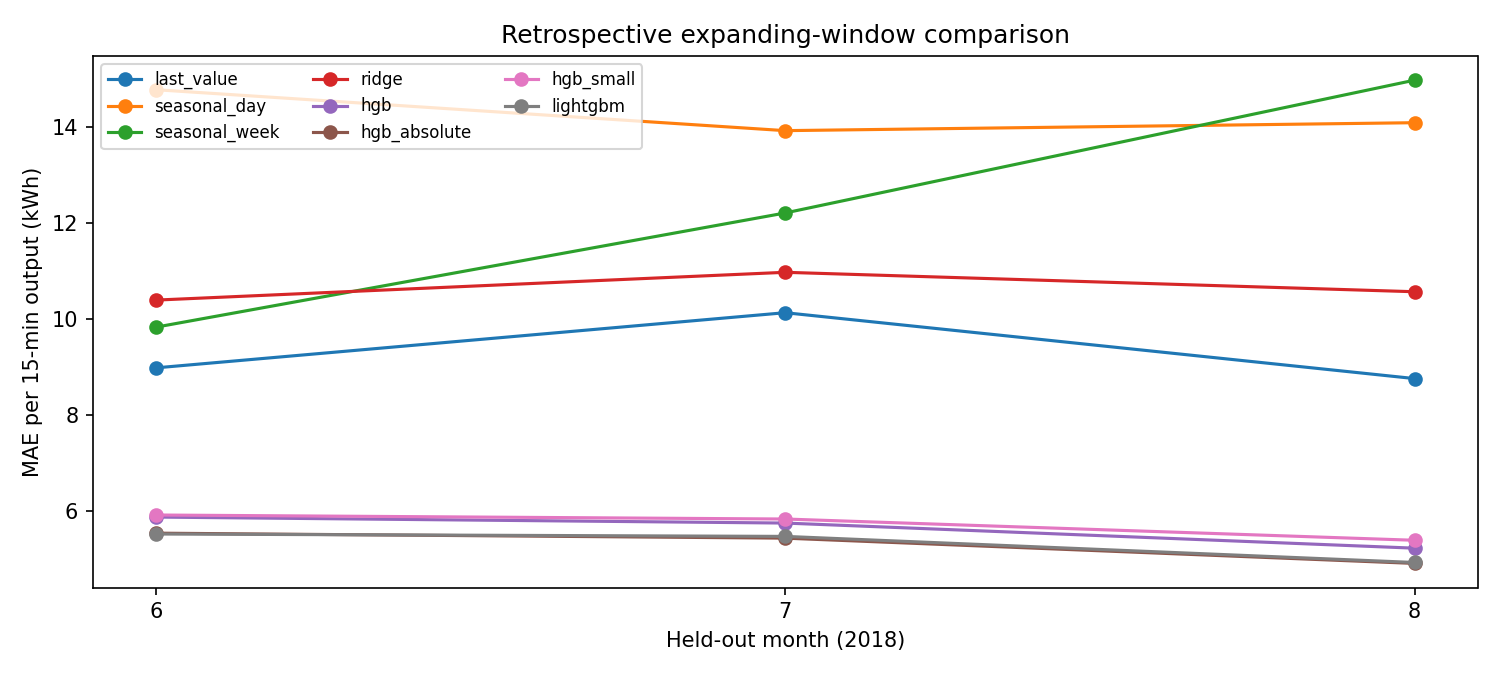

,month,variant,valid_rows,mae_per_step_kWh
0,6,base,2876,5.863650
1,6,two_deltas,2876,5.827137
2,6,no_calendar,2876,7.992577
3,6,no_rolling,2876,5.902730
4,7,base,2972,5.738716
5,7,two_deltas,2972,5.756540
6,7,no_calendar,2972,8.357182
7,7,no_rolling,2972,5.773024
8,8,base,2972,5.214750
9,8,two_deltas,2972,5.271599


In [2]:
display(pd.read_csv(STUDY/'walk_forward_summary.csv'))
display(Image(filename=str(STUDY/'walk_forward.png')))
display(pd.read_csv(STUDY/'feature_ablation.csv'))


## Phân tích lỗi của bản đang triển khai

Nhóm actual cao được xác định **sau khi có nhãn**, dùng p95 TRAIN. Không thể biết nhóm này tại thời điểm dự báo; kết quả không chứng minh nguyên nhân máy hay tiết kiệm thực.


,group_by,group,rows,mae_hour_kWh,mean_actual_minus_prediction_kWh,interval_coverage,upper_coverage
0,actual_energy,high,179,79.958358,79.618461,0.379888,0.379888
1,actual_energy,low,3290,3.217371,-1.904664,0.773252,0.873556
2,actual_energy,middle,2383,27.963285,1.182536,0.827528,0.926144


,minutes,rows,mae_kWh,rmse_kWh,mean_actual_minus_prediction_kWh
0,15,5852,3.766262,8.146744,0.497256
1,30,5852,4.551820,9.645465,0.451803
2,45,5852,5.292389,11.082922,0.492250
3,60,5852,5.845597,11.993215,0.404785


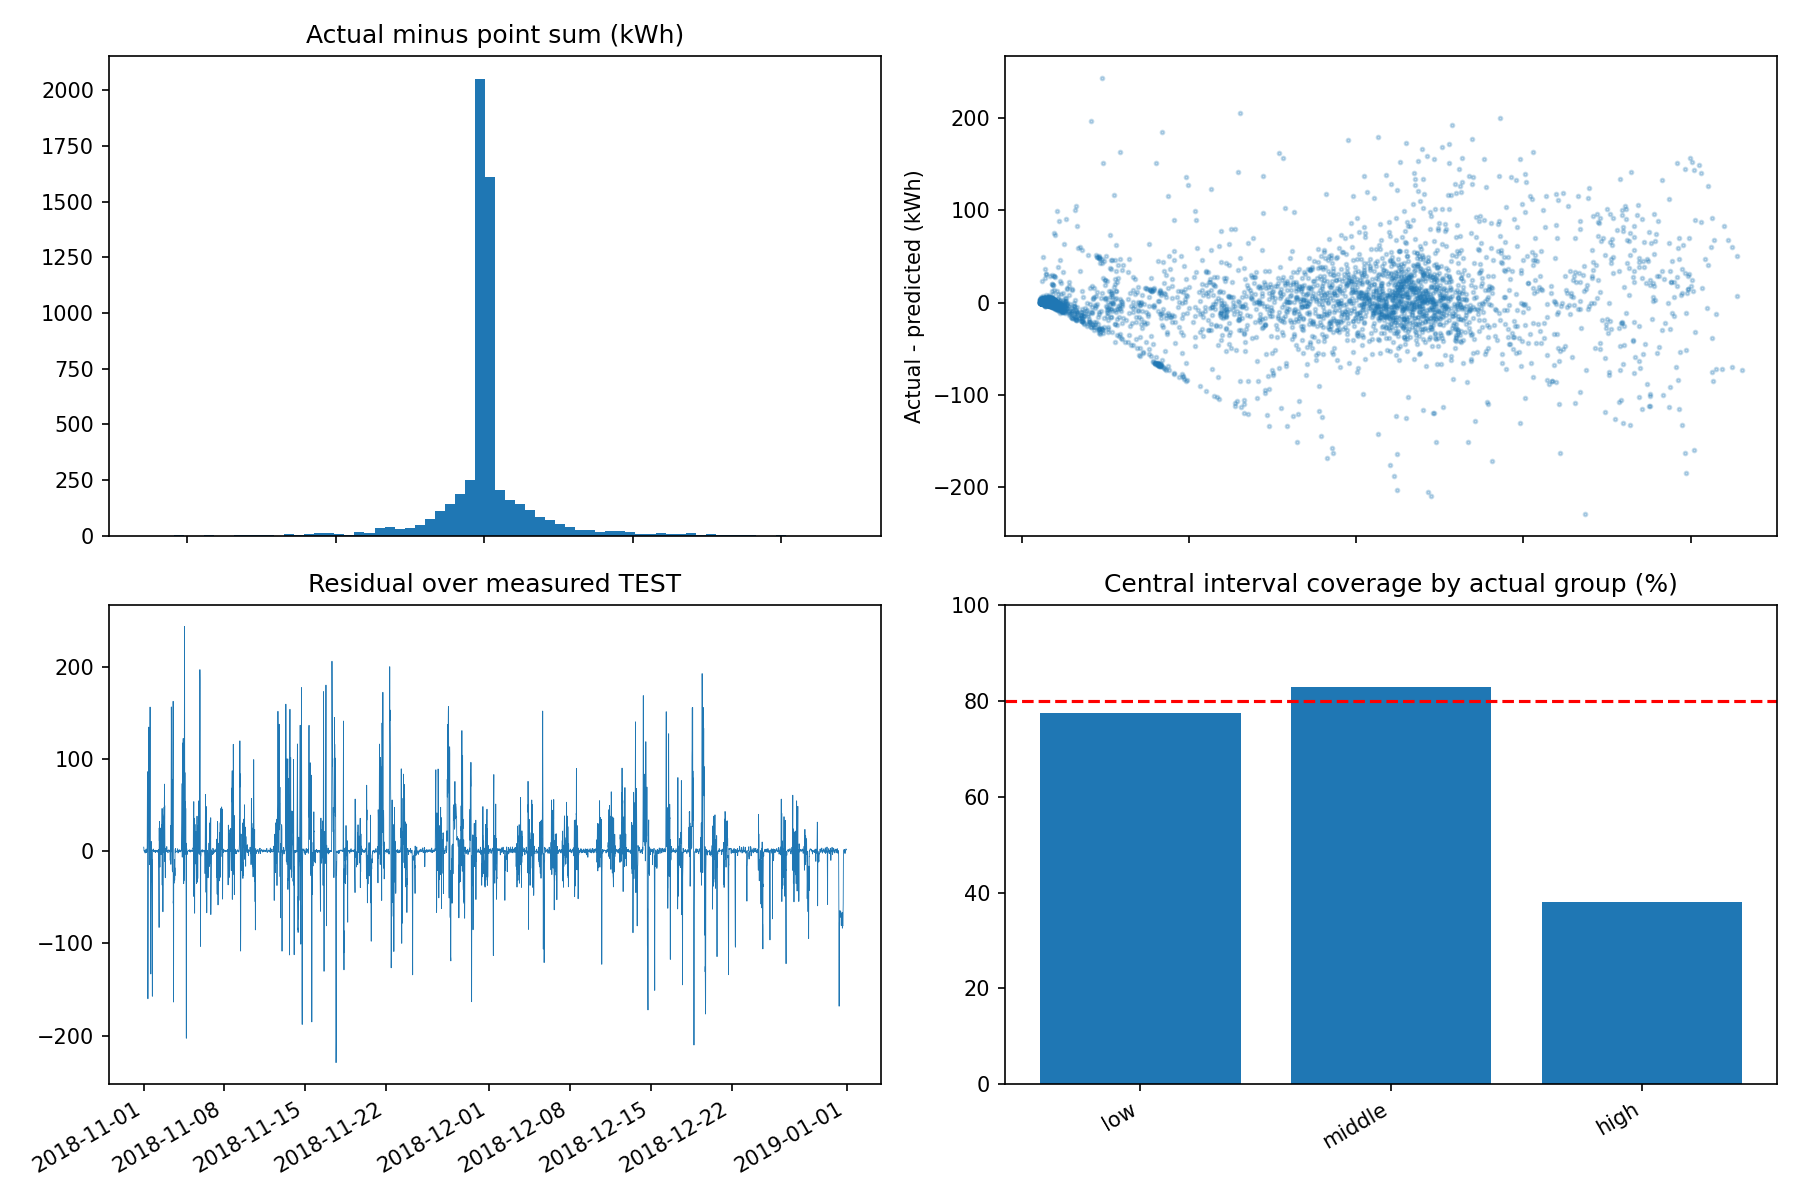

In [3]:
display(pd.read_csv(ERROR/'conditional_errors.csv').query("group_by == 'actual_energy'"))
display(pd.read_csv(ERROR/'horizon_errors.csv'))
display(Image(filename=str(ERROR/'residual_analysis.png')))


## Thử hiệu chỉnh biên trên và quyết định

Hai margin một phía được fit trên tháng 10. Không dùng TEST chọn mức 90% hay scale. Kết quả: độ phủ trên tăng nhưng FN vẫn 24, FP tăng; chưa có chi phí can thiệp nên không thay policy chính.


In [4]:
display(pd.read_csv(STUDY/'calibration_comparison.csv'))
display(pd.Series(new['splits']['test']['research_alert']))
display(pd.Series(json.loads((RUN/'monitoring_reference.json').read_text())))
display(pd.read_csv(ERROR/'monthly_metrics.csv'))


,method,rows,upper_coverage,high_actual_upper_coverage,mean_upper_addition_kWh,tp,fp,fn,tn,precision,recall,f1,false_positive_rate,false_discovery_rate
0,raw_p90,5852,0.853896,0.379888,0.000000,155,184,24,5489,0.457227,0.865922,0.598456,0.032434,0.542773
1,published_central80_upper,5852,0.879870,0.379888,0.311927,155,186,24,5487,0.454545,0.865922,0.596154,0.032787,0.545455
2,one_sided90_constant,5852,0.894908,0.379888,0.561220,155,187,24,5486,0.453216,0.865922,0.595010,0.032963,0.546784
3,one_sided90_normalized,5852,0.891490,0.396648,0.838858,155,193,24,5480,0.445402,0.865922,0.588235,0.034021,0.554598


rows                                                                           5852
tp                                                                              155
fp                                                                              186
fn                                                                               24
tn                                                                             5487
alert_rows                                                                      341
precision                                                                  0.454545
recall                                                                     0.865922
f1                                                                         0.596154
false_positive_rate                                                        0.032787
false_discovery_rate                                                       0.545455
roc_auc_ranking                                                             

model_sha256            7da262418ec055ef98c72efecd3ebeabf7735d5be5fb8a...
source_sha256           9b1cee6f9cb9cd9df2b95814ca90a9a2ff15b7f5f1fba0...
reference_period                   2018-10 calibration; no TEST reference
rows                                                                 2972
point_hour_mae_kWh                                               19.86274
central_coverage                                                 0.800808
window_labels                                                         672
mae_factor                                                            1.2
coverage_drop                                                         0.1
automatic_retraining                                                False
heuristic_only                                                       True
dtype: object

,month,origins,mae_per_step_kWh,mae_point_sum_kWh,coverage_after_calibration,tp,fp,fn,tn,precision,recall,f1
0,11,2880,5.916206,18.972792,0.801042,111,163,17,2589,0.405109,0.867188,0.552239
1,12,2972,3.844399,12.413380,0.766151,44,23,7,2898,0.656716,0.862745,0.745763


## Chạy demo và giải thích với thầy

1. `python -m scripts.serve_steel_demo --port 8765 --policy reports/steel/release_2026-10-11/locked_policy.json`
2. Chọn origin năm 2018; bốn actual hiện lần lượt sau từng bước 15 phút.
3. Đủ 1.344 nhãn liên tục mới đánh giá hai cửa sổ MAE/coverage của model mới, reference tháng 10 và đúng bundle hash.
4. Cảnh báo chỉ đề nghị người phụ trách kiểm tra. Không có P_limit/biểu giá/BESS hoặc tiết kiệm thực.
5. Đáp án khóa: `reports/steel/release_2026-10-16/results_summary.json`; kiểm và in bằng `python -m scripts.show_results`. Không cần chạy notebook để lấy số báo cáo.

Nguồn: [UCI](https://archive.ics.uci.edu/dataset/851/steel+industry+energy+consumption), [temporal validation](https://scikit-learn.org/1.8/modules/generated/sklearn.model_selection.TimeSeriesSplit.html), [HGB loss](https://scikit-learn.org/1.8/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html), [LightGBM parameters](https://lightgbm.readthedocs.io/en/v4.6.0/Parameters.html), [CQR](https://arxiv.org/abs/1905.03222). Liên hệ Case Study 4 của Lee ở phần dự báo nhu cầu và hỗ trợ quyết định; thiếu thông số để tối ưu điều khiển thiết bị/PHM.
